TASK 1- DATA UNDERSTANDING AND EXPLORATION

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/drive/MyDrive/DSA/exit exam/G1.csv')



In [2]:
df.head()

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


In [4]:
df.shape

(500, 30)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    object 
 2   Age                                 478 non-null    object 
 3   Gender                              484 non-null    object 
 4   Occupation_Status                   479 non-null    object 
 5   Country_Region                      480 non-null    object 
 6   Monthly_Income_Range                479 non-null    object 
 7   Shop_Most_Where                     484 non-null    object 
 8   Online_Shopping_Frequency           481 non-null    object 
 9   Preferred_Platform                  486 non-null    object 
 10  Primary_Device                      492 non-null    object 
 11  Top_Spending_Category               476 non-n

In [16]:
df.columns.tolist()

['Response_ID',
 'Timestamp',
 'Age',
 'Gender',
 'Occupation_Status',
 'Country_Region',
 'Monthly_Income_Range',
 'Shop_Most_Where',
 'Online_Shopping_Frequency',
 'Preferred_Platform',
 'Primary_Device',
 'Top_Spending_Category',
 'Review_Influence_Score',
 'Social_Ads_Influence_Score',
 'Price_Comparison_Frequency',
 'Discount_Importance_Score',
 'Follows_Brands_On_Social',
 'Likely_To_Buy_After_Ad_Score',
 'Makes_Shopping_List',
 'Impulse_Purchase_Frequency',
 'Return_Frequency',
 'Avg_Monthly_Spend_NonEssentials',
 'Preferred_Payment_Method',
 'Uses_BNPL_Installments',
 'Online_Shopping_Satisfaction_Score',
 'Trust_In_Online_Reviews_Score',
 'Regret_After_Purchase_Frequency',
 'Reason_Prefer_Online',
 'Reason_Prefer_InStore',
 'Best_Shopping_Mode']

In [11]:
df.select_dtypes(include='object').columns

Index(['Timestamp', 'Age', 'Gender', 'Occupation_Status', 'Country_Region',
       'Monthly_Income_Range', 'Shop_Most_Where', 'Online_Shopping_Frequency',
       'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category',
       'Follows_Brands_On_Social', 'Makes_Shopping_List', 'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments', 'Reason_Prefer_Online',
       'Reason_Prefer_InStore', 'Best_Shopping_Mode'],
      dtype='object')

In [3]:
#to identify numerical and categorical features
numerical_features = df.select_dtypes(include="number").columns.tolist()
categorical_features = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()


In [13]:
#to identify numerical and categorical features
feature_types = pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.astype(str).values
})

# Separate numerical and categorical features
numerical_features = df.select_dtypes(include="number").columns.tolist()
categorical_features = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

feature_types["Feature Category"] = feature_types["Feature"].apply(
    lambda column:
    "Numerical" if column in numerical_features
    else "Categorical"
)

display(feature_types)

,Feature,Data Type,Feature Category
0,Response_ID,int64,Numerical
1,Timestamp,object,Categorical
2,Age,object,Categorical
3,Gender,object,Categorical
4,Occupation_Status,object,Categorical
5,Country_Region,object,Categorical
6,Monthly_Income_Range,object,Categorical
7,Shop_Most_Where,object,Categorical
8,Online_Shopping_Frequency,object,Categorical
9,Preferred_Platform,object,Categorical


In [9]:
#Checking for missing values
df.isnull().sum()

,0
Response_ID,0
Timestamp,0
Age,22
Gender,16
Occupation_Status,21
Country_Region,20
Monthly_Income_Range,21
Shop_Most_Where,16
Online_Shopping_Frequency,19
Preferred_Platform,14


In [10]:
#checking for duplicates
df.duplicated().sum()

np.int64(0)

In [14]:
#summary statistics
df.describe()

,Response_ID,Review_Influence_Score,Social_Ads_Influence_Score,Price_Comparison_Frequency,Discount_Importance_Score,Likely_To_Buy_After_Ad_Score,Impulse_Purchase_Frequency,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency
count,500.000000,485.000000,479.000000,474.000000,477.000000,475.000000,484.000000,457.000000,450.000000,448.000000
mean,250.500000,3.053608,3.079332,4.139241,3.821803,3.016842,2.590909,7.126915,6.160000,2.187500
std,144.481833,1.128707,1.228144,0.943219,0.989284,1.109857,1.162741,1.592636,1.918425,0.902705
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000
25%,125.750000,2.000000,2.000000,4.000000,3.000000,2.000000,2.000000,6.000000,5.000000,1.000000
50%,250.500000,3.000000,3.000000,4.000000,4.000000,3.000000,2.000000,7.000000,6.000000,2.000000
75%,375.250000,4.000000,4.000000,5.000000,5.000000,4.000000,3.000000,8.000000,7.000000,3.000000
max,500.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,10.000000,10.000000,4.000000


In [15]:
df.describe(include="all")

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
count,500.000000,500,478,484,479,480,479,484,481,486,...,483,480,485,488,457.000000,450.000000,448.000000,446,455,449
unique,NaN,500,43,3,5,18,4,3,4,4,...,3,5,4,3,NaN,NaN,NaN,4,4,3
top,NaN,01/08/2026 12:30:25,21,Male,Student,India,"Under $1,000",Equal mix,Occasionally,Global marketplace (Amazon etc.),...,Sometimes,Under $50,Digital wallet,"No, never",NaN,NaN,NaN,More variety,Try product before buying,Online
freq,NaN,1,67,256,238,66,257,248,240,141,...,213,179,183,290,NaN,NaN,NaN,170,145,218
mean,250.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,7.126915,6.160000,2.187500,NaN,NaN,NaN
std,144.481833,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.592636,1.918425,0.902705,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,2.000000,1.000000,1.000000,NaN,NaN,NaN
25%,125.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,6.000000,5.000000,1.000000,NaN,NaN,NaN
50%,250.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,7.000000,6.000000,2.000000,NaN,NaN,NaN
75%,375.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,8.000000,7.000000,3.000000,NaN,NaN,NaN


In [17]:
#visualize the distribution of target variable
print(df["Best_Shopping_Mode"].unique())
print(df["Best_Shopping_Mode"].value_counts(dropna=False))

['Online' 'Offline' 'Equal / both' nan]
Best_Shopping_Mode
Online          218
Offline         118
Equal / both    113
NaN              51
Name: count, dtype: int64


In [20]:
target_column = "Best_Shopping_Mode"

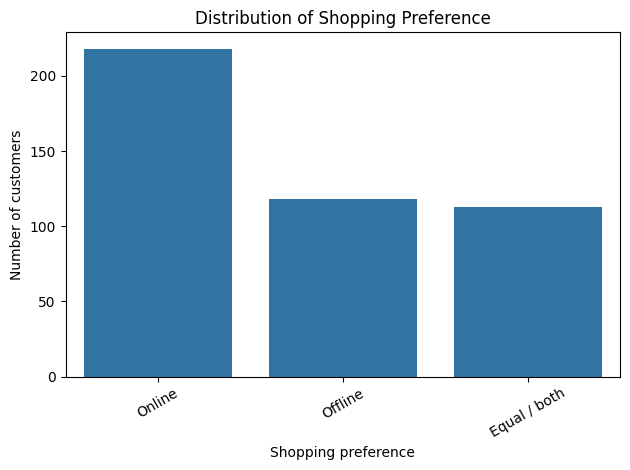

In [21]:
sns.countplot(data=df, x=target_column)
plt.title("Distribution of Shopping Preference")
plt.xlabel("Shopping preference")
plt.ylabel("Number of customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [22]:
df["Best_Shopping_Mode"].value_counts()

(df["Best_Shopping_Mode"].value_counts(normalize=True) * 100).round(2)

,proportion
Best_Shopping_Mode,
Online,48.55
Offline,26.28
Equal / both,25.17


1.Is the dataset balanced with respect to shopping mode?

In [23]:
target = "Best_Shopping_Mode"

display(df[target].value_counts().to_frame("Count"))
display((df[target].value_counts(normalize=True) * 100).round(1).to_frame("Percent"))

,Count
Best_Shopping_Mode,
Online,218
Offline,118
Equal / both,113


,Percent
Best_Shopping_Mode,
Online,48.6
Offline,26.3
Equal / both,25.2


Answer-1. The dataset is moderately imbalanced.

Online: 218 respondents (48.6%)

Offline: 118 respondents (26.3%)

Equal/Both: 113 respondents (25.2%)

Online is the largest category and is about 1.8 times the size of Offline and nearly 1.9 times the size of Equal/Both. Offline and Equal/Both are proportionally similar. Therefore, the target variable is not perfectly balanced, and Online may receive stronger weighting during model training.

2. Whivh demographic group appears to dominate the survey?

In [24]:
display(df["Gender"].value_counts().to_frame("Count"))
display(df["Occupation_Status"].value_counts().to_frame("Count"))
display(df["Country_Region"].value_counts().to_frame("Count"))
display(df["Monthly_Income_Range"].value_counts().to_frame("Count"))

,Count
Gender,
Male,256
Female,177
Prefer not to say,51


,Count
Occupation_Status,
Student,238
Employed full-time,118
Employed part-time,71
Self-employed,33
Unemployed,19


,Count
Country_Region,
India,66
United States,56
Brazil,38
Mexico,35
Kenya,26
Indonesia,26
Egypt,25
Philippines,23
Nigeria,23


,Count
Monthly_Income_Range,
"Under $1,000",257
"$1,000-3,000",122
"$3,000-6,000",65
"$6,000+",35


Answer-Male, student respondents earning under $1,000 per month.

Gender: Males = 256, the largest gender category.

Occupation: Students = 238, the largest occupation category.

Income: Under $1,000 = 257, the largest income category.

Country: India = 66, followed by the United States (56).

Why: These categories have the highest counts because the dataset is concentrated more heavily among that demographic segment. The pattern may reflect the survey’s recruitment or sampling method rather than consumer behavior across the global population.

3.What initial business insights can you infer from data

In [26]:
display(pd.crosstab(df["Gender"], df[target], normalize="index").round(2))
display(pd.crosstab(df["Occupation_Status"], df[target], normalize="index").round(2))
display(pd.crosstab(df["Monthly_Income_Range"], df[target], normalize="index").round(2))

Best_Shopping_Mode,Equal / both,Offline,Online
Gender,,,
Female,0.22,0.28,0.50
Male,0.27,0.26,0.47
Prefer not to say,0.24,0.22,0.53


Best_Shopping_Mode,Equal / both,Offline,Online
Occupation_Status,,,
Employed full-time,0.25,0.22,0.54
Employed part-time,0.14,0.41,0.45
Self-employed,0.23,0.32,0.45
Student,0.31,0.22,0.46
Unemployed,0.12,0.41,0.47


Best_Shopping_Mode,Equal / both,Offline,Online
Monthly_Income_Range,,,
"$1,000-3,000",0.28,0.19,0.52
"$3,000-6,000",0.23,0.37,0.40
"$6,000+",0.33,0.21,0.45
"Under $1,000",0.24,0.27,0.48


Answer-Online shopping is the most preferred option across all gender, occupation, and income groups (40–54%).

Offline preference is comparatively higher among part-time and unemployed respondents (41%) and those earning $3,000–$6,000 (37%).

 Students and respondents earning $6,000 or more show relatively stronger interest in using both modes. These patterns can guide marketing, but they show associations—not causes.

#TASK 2. DATA PREPROCESSING

Handling missing values

In [29]:
# Remove rows with a missing target
df = df.dropna(subset=["Best_Shopping_Mode"]).copy()

# Fill missing numerical values with each column's median
numerical_columns = df.select_dtypes(include="number").columns
df[numerical_columns] = df[numerical_columns].fillna(
    df[numerical_columns].median()
)

# Fill missing categorical values with each column's most frequent value
categorical_columns = df.select_dtypes(include=["object", "category"]).columns

for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

# Check that missing values have been handled
df.isnull().sum()

,0
Response_ID,0
Timestamp,0
Age,0
Gender,0
Occupation_Status,0
Country_Region,0
Monthly_Income_Range,0
Shop_Most_Where,0
Online_Shopping_Frequency,0
Preferred_Platform,0


Remove or justify duplicate handling





In [30]:
df.duplicated().sum()

np.int64(0)

The duplicate check returned 0, meaning no rows were identical across all columns. Therefore, no records were removed; removing any would unnecessarily reduce the dataset

In [31]:
#Verify cleaning

print(df.isnull().sum())

print("Duplicates:", df.duplicated().sum())

print("Shape:", df.shape)

Response_ID                           0
Timestamp                             0
Age                                   0
Gender                                0
Occupation_Status                     0
Country_Region                        0
Monthly_Income_Range                  0
Shop_Most_Where                       0
Online_Shopping_Frequency             0
Preferred_Platform                    0
Primary_Device                        0
Top_Spending_Category                 0
Review_Influence_Score                0
Social_Ads_Influence_Score            0
Price_Comparison_Frequency            0
Discount_Importance_Score             0
Follows_Brands_On_Social              0
Likely_To_Buy_After_Ad_Score          0
Makes_Shopping_List                   0
Impulse_Purchase_Frequency            0
Return_Frequency                      0
Avg_Monthly_Spend_NonEssentials       0
Preferred_Payment_Method              0
Uses_BNPL_Installments                0
Online_Shopping_Satisfaction_Score    0


Encode categorical variables

In [32]:
#Step 1: Check categorical columns
df.select_dtypes(include='object').columns

Index(['Timestamp', 'Age', 'Gender', 'Occupation_Status', 'Country_Region',
       'Monthly_Income_Range', 'Shop_Most_Where', 'Online_Shopping_Frequency',
       'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category',
       'Follows_Brands_On_Social', 'Makes_Shopping_List', 'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments', 'Reason_Prefer_Online',
       'Reason_Prefer_InStore', 'Best_Shopping_Mode'],
      dtype='object')

In [38]:
target = "Best_Shopping_Mode"

# Separate features from the target
X = df.drop(columns=[target])
X = X.drop(
    columns=["Response_ID", "Timestamp"],
    errors="ignore"
)

# Remove identifier and timestamp columns from the features
categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns

# One-hot encode the remaining categorical features
X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    dtype=int
)

print("Encoded shape:", X_encoded.shape)
X_encoded.head()

Encoded shape: (449, 128)


,Review_Influence_Score,Social_Ads_Influence_Score,Price_Comparison_Frequency,Discount_Importance_Score,Likely_To_Buy_After_Ad_Score,Impulse_Purchase_Frequency,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Age_...,...,"Uses_BNPL_Installments_Yes, occasionally","Uses_BNPL_Installments_Yes, regularly",Reason_Prefer_Online_Better prices,Reason_Prefer_Online_Convenience,Reason_Prefer_Online_More variety,Reason_Prefer_Online_Not applicable,Reason_Prefer_InStore_No delivery wait,Reason_Prefer_InStore_Not applicable,Reason_Prefer_InStore_Trust,Reason_Prefer_InStore_Try product before buying
0,2.0,4.0,2.0,4.0,4.0,3.0,6.0,7.0,2.0,0,...,1,0,0,0,1,0,1,0,0,0
1,4.0,2.0,5.0,2.0,3.0,4.0,5.0,8.0,3.0,0,...,0,0,0,0,1,0,0,0,0,1
2,3.0,3.0,5.0,3.0,2.0,3.0,7.0,6.0,2.0,0,...,0,0,1,0,0,0,0,0,1,0
3,3.0,4.0,3.0,2.0,5.0,5.0,8.0,7.0,3.0,0,...,0,0,1,0,0,0,0,0,0,1
4,2.0,1.0,4.0,3.0,1.0,2.0,6.0,8.0,2.0,0,...,0,0,0,1,0,0,0,0,1,0


In [39]:
print("Features:", X_encoded.shape)
print("Target:", y.shape)

# Confirm row counts match
print("Aligned:", X_encoded.shape[0] == y.shape[0])
print("Missing feature values:", X_encoded.isna().sum().sum())

Features: (449, 128)
Target: (449,)
Aligned: True
Missing feature values: 0


In [42]:
#splitting
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (359, 128)
Testing features: (90, 128)
Training target: (359,)
Testing target: (90,)


In [41]:
y.value_counts(normalize=True)

,proportion
Best_Shopping_Mode,
Online,0.485523
Offline,0.262806
Equal / both,0.251670


1. Which preprocessing decisions were most important, and why?

The most important decisions were:

Excluding Response_ID and Timestamp from the predictors: These are identifiers or record metadata, not meaningful indicators of a person’s shopping mode. Including them could lead the model to learn irrelevant patterns.
Separating Best_Shopping_Mode as the target: This ensures the model learns to predict the outcome rather than using it as an input feature.
One-hot encoding categorical predictors: This converts categories into numeric features the model can use without implying that one category is greater than another.
Using a stratified train/test split: Stratification keeps the proportions of Online, Offline, and Equal / both similar in both sets, which matters because the classes have different proportions.
Checking for missing values and feature-target alignment: Your checks showed 449 rows in both features and target, with no missing feature values, so the model can use the rows consistently.

2. How might improper handling of missing values affect predictions?

If missing values are ignored or handled inconsistently, some models may fail to train, or rows may be dropped unnecessarily. If missing values are filled with inappropriate values, the model may learn misleading patterns and make less accurate predictions. For example, replacing missing categories with a common category can falsely suggest that those records belong to that category.

#3.EDA

In [45]:
df = pd.read_csv("/content/drive/MyDrive/DSA/exit exam/G1.csv")

print(df.shape)
print(df.head())
print(df.columns.tolist())

(500, 30)
   Response_ID            Timestamp Age  Gender   Occupation_Status  \
0            1  01/08/2026 12:30:25  20    Male                 NaN   
1            2  21/06/2026 13:52:02  24    Male  Employed part-time   
2            3  15/08/2026 04:24:18  22  Female             Student   
3            4  23/06/2026 21:24:21  20    Male             Student   
4            5  20/08/2026 16:24:47  41    Male  Employed full-time   

  Country_Region Monthly_Income_Range Shop_Most_Where  \
0    Philippines         Under $1,000       Equal mix   
1         Brazil         Under $1,000   In-store only   
2          India         Under $1,000       Equal mix   
3            NaN         Under $1,000   In-store only   
4  United States         $1,000-3,000       Equal mix   

  Online_Shopping_Frequency Preferred_Platform  ... Return_Frequency  \
0                     Often    Physical stores  ...            Never   
1                     Often   Local e-commerce  ...            Often   
2   

In [46]:
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status', 'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where', 'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category', 'Review_Influence_Score', 'Social_Ads_Influence_Score', 'Price_Comparison_Frequency', 'Discount_Importance_Score', 'Follows_Brands_On_Social', 'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List', 'Impulse_Purchase_Frequency', 'Return_Frequency', 'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method', 'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score', 'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency', 'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode']

Data types:
Response_ID                             int64
Timestamp                              object
Age                                    object
Gender                                 object
Occupation_Status                      object
Country_Region       

In [47]:
#missing value counts
missing_count = df.isna().sum()

print(missing_count[missing_count > 0]
      .sort_values(ascending=False))

Reason_Prefer_Online                  54
Regret_After_Purchase_Frequency       52
Best_Shopping_Mode                    51
Trust_In_Online_Reviews_Score         50
Reason_Prefer_InStore                 45
Online_Shopping_Satisfaction_Score    43
Price_Comparison_Frequency            26
Likely_To_Buy_After_Ad_Score          25
Top_Spending_Category                 24
Makes_Shopping_List                   24
Discount_Importance_Score             23
Age                                   22
Occupation_Status                     21
Monthly_Income_Range                  21
Social_Ads_Influence_Score            21
Avg_Monthly_Spend_NonEssentials       20
Country_Region                        20
Online_Shopping_Frequency             19
Return_Frequency                      17
Gender                                16
Impulse_Purchase_Frequency            16
Shop_Most_Where                       16
Review_Influence_Score                15
Preferred_Payment_Method              15
Preferred_Platfo

In [48]:
#missing value percentage
missing_percentage = (df.isna().sum() / df.shape[0]) * 100

print(missing_percentage[missing_percentage > 0]
      .sort_values(ascending=False))


Reason_Prefer_Online                  10.8
Regret_After_Purchase_Frequency       10.4
Best_Shopping_Mode                    10.2
Trust_In_Online_Reviews_Score         10.0
Reason_Prefer_InStore                  9.0
Online_Shopping_Satisfaction_Score     8.6
Price_Comparison_Frequency             5.2
Likely_To_Buy_After_Ad_Score           5.0
Top_Spending_Category                  4.8
Makes_Shopping_List                    4.8
Discount_Importance_Score              4.6
Age                                    4.4
Occupation_Status                      4.2
Monthly_Income_Range                   4.2
Social_Ads_Influence_Score             4.2
Avg_Monthly_Spend_NonEssentials        4.0
Country_Region                         4.0
Online_Shopping_Frequency              3.8
Return_Frequency                       3.4
Gender                                 3.2
Impulse_Purchase_Frequency             3.2
Shop_Most_Where                        3.2
Review_Influence_Score                 3.0
Preferred_P

In [49]:
#duplicate rows
df.duplicated().sum()

np.int64(0)

In [50]:
#target counts
target = "Best_Shopping_Mode"

df[target].value_counts(dropna=False)

,count
Best_Shopping_Mode,
Online,218
Offline,118
Equal / both,113
NaN,51


age vs shopping mode

In [51]:
#converting age to numeric
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

In [61]:
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

df.groupby("Best_Shopping_Mode")["Age"].describe()

,count,mean,std,min,25%,50%,75%,max
Best_Shopping_Mode,,,,,,,,
Equal / both,100.0,23.570000,7.114156,16.0,19.0,21.0,25.0,48.0
Offline,114.0,25.745614,7.213325,16.0,20.0,24.0,31.0,48.0
Online,209.0,25.124402,7.521369,16.0,20.0,22.0,30.0,50.0


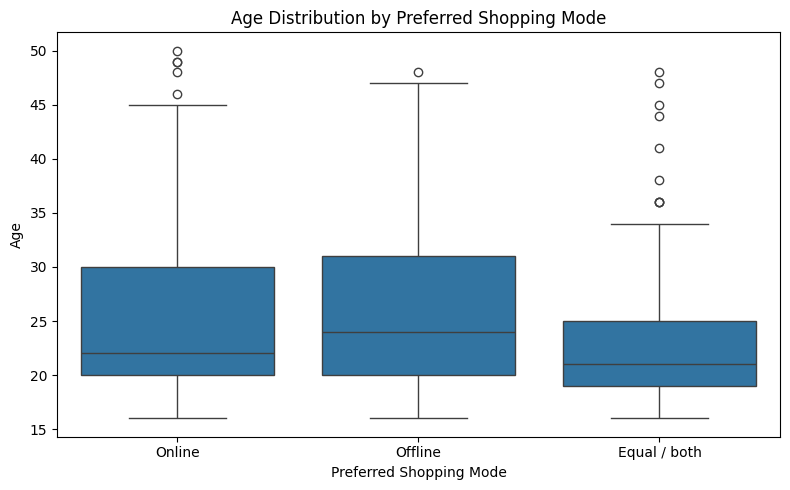

In [62]:
#creating boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Best_Shopping_Mode", y="Age")
plt.title("Age Distribution by Preferred Shopping Mode")
plt.xlabel("Preferred Shopping Mode")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

income vs spending

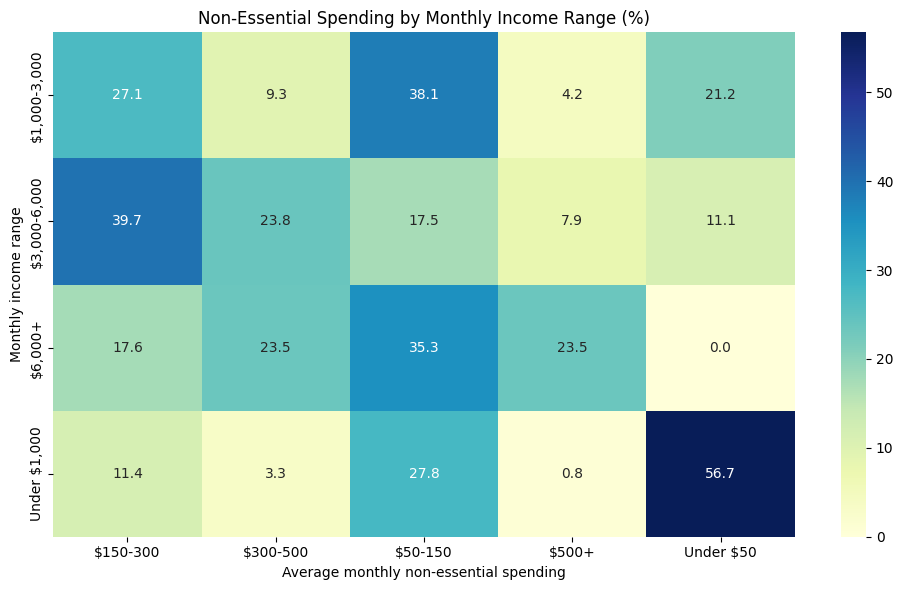

In [57]:
income_spending = pd.crosstab(
    df["Monthly_Income_Range"],
    df["Avg_Monthly_Spend_NonEssentials"],
    normalize="index"
) * 100

plt.figure(figsize=(10, 6))
sns.heatmap(income_spending, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Non-Essential Spending by Monthly Income Range (%)")
plt.xlabel("Average monthly non-essential spending")
plt.ylabel("Monthly income range")
plt.tight_layout()
plt.show()

online shopping frequency

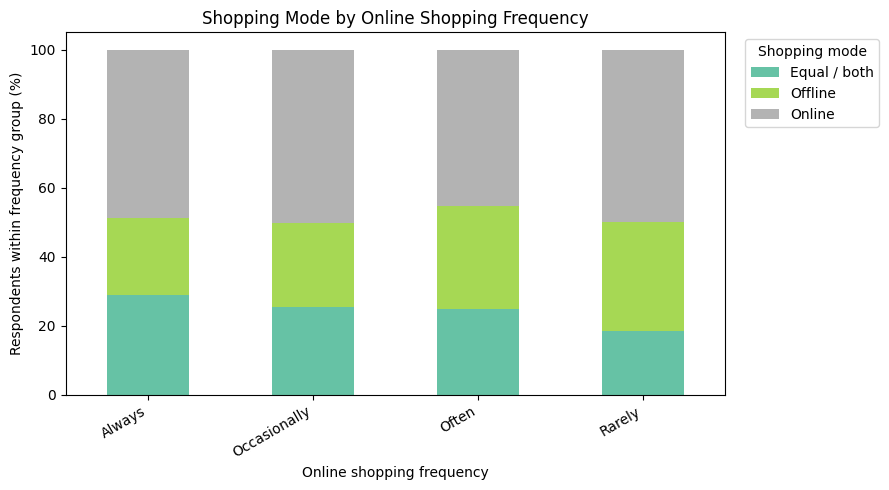

In [58]:
frequency_by_mode = pd.crosstab(
    df["Online_Shopping_Frequency"],
    df[target],
    normalize="index"
) * 100

frequency_by_mode.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    colormap="Set2"
)
plt.title("Shopping Mode by Online Shopping Frequency")
plt.xlabel("Online shopping frequency")
plt.ylabel("Respondents within frequency group (%)")
plt.legend(title="Shopping mode", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Satisfaction and review influence scores

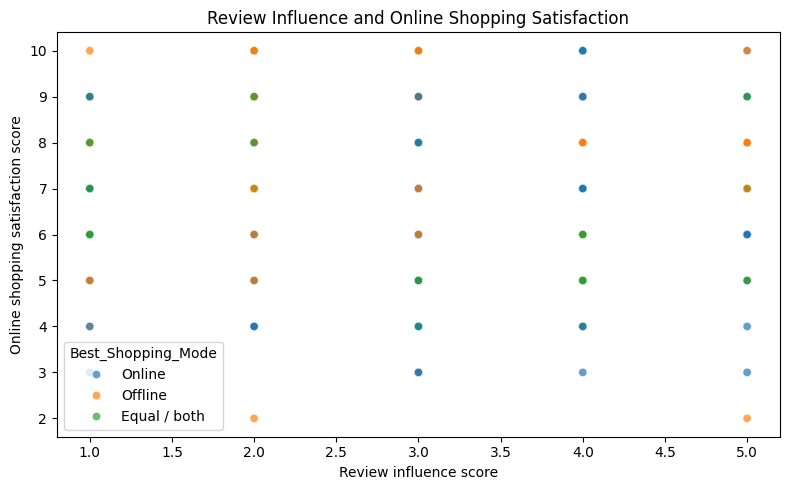

In [59]:
score_data = df.dropna(
    subset=[
        "Online_Shopping_Satisfaction_Score",
        "Review_Influence_Score",
        target
    ]
)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=score_data,
    x="Review_Influence_Score",
    y="Online_Shopping_Satisfaction_Score",
    hue=target,
    alpha=0.7
)
plt.title("Review Influence and Online Shopping Satisfaction")
plt.xlabel("Review influence score")
plt.ylabel("Online shopping satisfaction score")
plt.tight_layout()
plt.show()

Payment method distribution

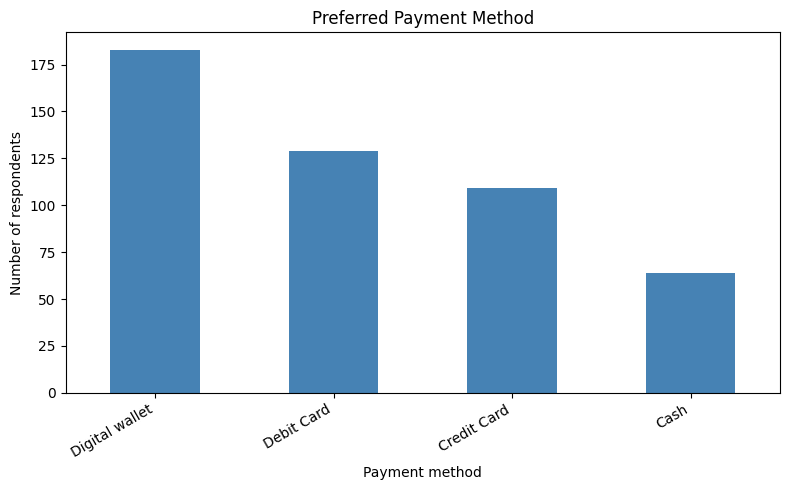

In [60]:
payment_counts = df["Preferred_Payment_Method"].value_counts()

plt.figure(figsize=(8, 5))
payment_counts.plot(kind="bar", color="steelblue")
plt.title("Preferred Payment Method")
plt.xlabel("Payment method")
plt.ylabel("Number of respondents")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

1.

2.

3.

#Task4 Machine Learning Model

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from sklearn.inspection import permutation_importance

Train and evaluate models

In [64]:
target = "Best_Shopping_Mode"

# Exclude rows without a target label; these cannot be used for supervised training
model_df = df.dropna(subset=[target]).copy()

# Remove identifier/metadata columns if they exist
columns_to_drop = [target, "Response_ID", "Timestamp"]
X = model_df.drop(columns=columns_to_drop, errors="ignore")
y = model_df[target]

print("Features:", X.shape)
print("Target counts:")
print(y.value_counts())

Features: (449, 27)
Target counts:
Best_Shopping_Mode
Online          218
Offline         118
Equal / both    113
Name: count, dtype: int64


In [65]:
#split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (359, 27)
Test set: (90, 27)


In [66]:
#setup preprocessing
numeric_columns = X_train.select_dtypes(include="number").columns
categorical_columns = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns

numeric_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessing, numeric_columns),
    ("categorical", categorical_preprocessing, categorical_columns)
])

print("Numeric columns:", list(numeric_columns))
print("Categorical columns:", list(categorical_columns))

Numeric columns: ['Age', 'Review_Influence_Score', 'Social_Ads_Influence_Score', 'Price_Comparison_Frequency', 'Discount_Importance_Score', 'Likely_To_Buy_After_Ad_Score', 'Impulse_Purchase_Frequency', 'Online_Shopping_Satisfaction_Score', 'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency']
Categorical columns: ['Gender', 'Occupation_Status', 'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where', 'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category', 'Follows_Brands_On_Social', 'Makes_Shopping_List', 'Return_Frequency', 'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method', 'Uses_BNPL_Installments', 'Reason_Prefer_Online', 'Reason_Prefer_InStore']


In [67]:
#define 4 models
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    ),
    "Support Vector Machine": SVC(
        class_weight="balanced",
        random_state=42
    )
}


In [68]:
#train and evaluate models
results = []
fitted_models = {}

for name, classifier in models.items():
    model = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    fitted_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "Macro precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results).sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

results_df.round(3)

,Model,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1
0,Decision Tree,0.567,0.504,0.487,0.504,0.491
1,Support Vector Machine,0.500,0.441,0.456,0.441,0.448
2,Random Forest,0.544,0.455,0.434,0.455,0.432
3,Logistic Regression,0.433,0.402,0.424,0.402,0.411


In [69]:
best_model_name = results_df.loc[0, "Model"]
best_model = fitted_models[best_model_name]

print("Best model:", best_model_name)

Best model: Decision Tree


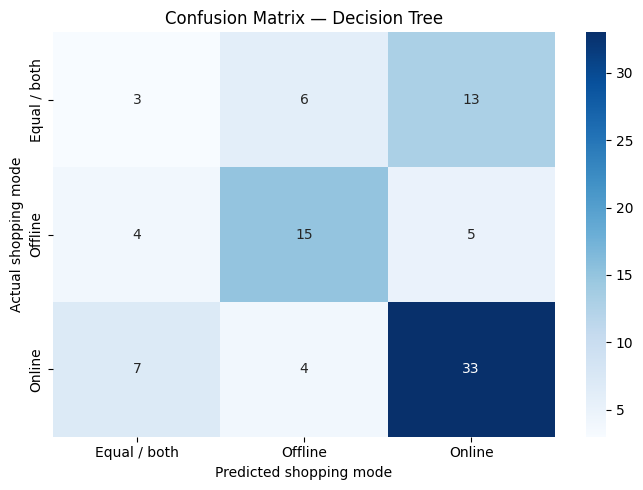

In [70]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

best_predictions = best_model.predict(X_test)
class_labels = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=class_labels
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted shopping mode")
plt.ylabel("Actual shopping mode")
plt.tight_layout()
plt.show()

In [71]:
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Standard Deviation": importance.importances_std
}).sort_values("Importance", ascending=False)

importance_df.head(15)

,Feature,Importance,Standard Deviation
5,Shop_Most_Where,0.132833,0.044125
0,Age,0.015157,0.035249
13,Discount_Importance_Score,0.012771,0.011467
18,Return_Frequency,0.012512,0.006205
22,Online_Shopping_Satisfaction_Score,0.012453,0.018602
11,Social_Ads_Influence_Score,0.005151,0.008064
25,Reason_Prefer_Online,0.004994,0.011817
20,Preferred_Payment_Method,0.003961,0.019087
24,Regret_After_Purchase_Frequency,0.003931,0.010392
7,Preferred_Platform,0.002692,0.009970


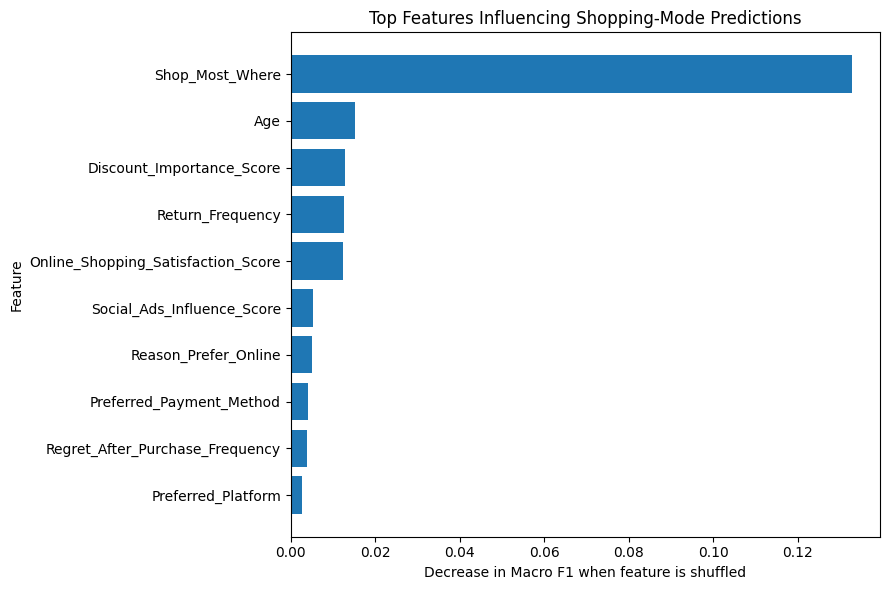

In [72]:
top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.title("Top Features Influencing Shopping-Mode Predictions")
plt.xlabel("Decrease in Macro F1 when feature is shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [73]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [74]:
tree_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

tree_parameters = {
    "classifier__max_depth": [None, 3, 5, 8, 12],
    "classifier__min_samples_split": [2, 5, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 5, 10],
    "classifier__class_weight": [None, "balanced"]
}

tree_search = RandomizedSearchCV(
    estimator=tree_pipeline,
    param_distributions=tree_parameters,
    n_iter=25,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

tree_search.fit(X_train, y_train)

print("Best Decision Tree cross-validation Macro F1:",
      round(tree_search.best_score_, 3))
print("Best parameters:", tree_search.best_params_)

Best Decision Tree cross-validation Macro F1: 0.569
Best parameters: {'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 10, 'classifier__max_depth': 3, 'classifier__class_weight': 'balanced'}


In [75]:
forest_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

forest_parameters = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 5, 10, 15],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2", None],
    "classifier__class_weight": [None, "balanced", "balanced_subsample"]
}

forest_search = RandomizedSearchCV(
    estimator=forest_pipeline,
    param_distributions=forest_parameters,
    n_iter=25,
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

forest_search.fit(X_train, y_train)

print("Best Random Forest cross-validation Macro F1:",
      round(forest_search.best_score_, 3))
print("Best parameters:", forest_search.best_params_)

Best Random Forest cross-validation Macro F1: 0.613
Best parameters: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': None, 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced_subsample'}


In [76]:
best_model_name = "Tuned Random Forest"
best_model = forest_search.best_estimator_

print("Selected model:", best_model_name)

Selected model: Tuned Random Forest


In [77]:
#evaluate test set
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

test_predictions = best_model.predict(X_test)

print("Test accuracy:",
      round(accuracy_score(y_test, test_predictions), 3))
print("Test balanced accuracy:",
      round(balanced_accuracy_score(y_test, test_predictions), 3))
print("Test macro precision:",
      round(precision_score(y_test, test_predictions,
                            average="macro", zero_division=0), 3))
print("Test macro recall:",
      round(recall_score(y_test, test_predictions,
                         average="macro", zero_division=0), 3))
print("Test Macro-F1:",
      round(f1_score(y_test, test_predictions,
                     average="macro", zero_division=0), 3))

Test accuracy: 0.511
Test balanced accuracy: 0.475
Test macro precision: 0.485
Test macro recall: 0.475
Test Macro-F1: 0.476


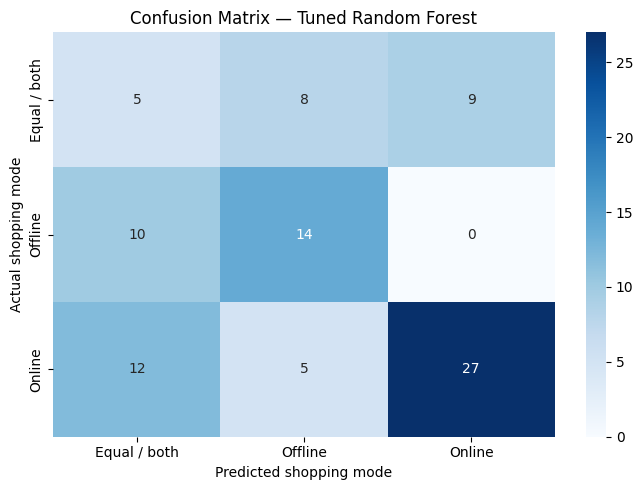

In [78]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

class_labels = sorted(y.unique())
cm = confusion_matrix(y_test, test_predictions, labels=class_labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title("Confusion Matrix — Tuned Random Forest")
plt.xlabel("Predicted shopping mode")
plt.ylabel("Actual shopping mode")
plt.tight_layout()
plt.show()

1.The Decision Tree achieved the strongest test performance, with 56.7% accuracy and 0.491 macro-F1.
It outperformed Random Forest and SVM on this split, but overall performance remains moderate.
The permutation-importance ranking indicates which features were most useful to the model.
Report feature names and their importance values from importance_df; do not call them causal effects.
The values in the confusion matrix show how often each shopping mode was predicted correctly or confused.

In [79]:
import joblib

joblib.dump(forest_search.best_estimator_, "shopping_model.joblib")
print("Model saved as shopping_model.joblib")

Model saved as shopping_model.joblib


In [80]:
!pip install -q flask pyngrok

In [82]:
import joblib
from google.colab import files

model_bundle = {
    "model": forest_search.best_estimator_,
    "feature_columns": list(X_train.columns),
    "numeric_features": list(X_train.select_dtypes(include="number").columns),
    "categorical_features": [
        col for col in X_train.columns
        if col not in X_train.select_dtypes(include="number").columns
    ],
    "categorical_options": {
        col: X_train[col].dropna().unique().tolist()
        for col in X_train.columns
        if col not in X_train.select_dtypes(include="number").columns
    }
}

joblib.dump(model_bundle, "shopping_model_bundle.joblib")
files.download("shopping_model_bundle.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [83]:
import sklearn
print(sklearn.__version__)

1.6.1
